# Week 5 Deliverable: Vision-Language Models (VQA, Captioning, Multimodal Embeddings)

## 1. Setup

In [31]:
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip install -q -U transformers accelerate ultralytics datasets jsonschema python-dateutil pytesseract

import os, re, io, json, time, random, difflib
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import pytesseract
from PIL import Image
from dateutil import parser as dateparser
from jsonschema import validate, ValidationError
from IPython.display import display, Markdown
from ultralytics.utils import ASSETS

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "|", torch.cuda.get_device_name(0) if dev == "cuda" else "no GPU: the VLM needs one")
RESULTS = {}

device: cuda | Tesla T4


## 2. Settings and the Week 4 outputs

For the three-way comparison, this notebook needs the **outputs of the Week 4 pipelines on the same invoices**. Add this cell at the **end of your Week 4 notebook**, run it, and keep the file it writes (commit it to your repo or download it):

```python
export = {name: {cond: OUTS[(name, cond)] for cond in ["clean", "degraded"]} for name in SYSTEMS}
Path("week4_outputs.json").write_text(json.dumps(export, default=str))
```

Then upload `week4_outputs.json` to this Colab session (folder icon in the left sidebar) and set `WEEK4_OUTPUTS = "/content/week4_outputs.json"` below. Both notebooks build the held-out set with the same seed and the same `N_TEST` and `N_HARD`, so the documents are identical. Without the file, this notebook still works, and the comparison shows the VLM only.

In [32]:
# ---- Settings ----
N_TEST, N_HARD = 20, 8            # keep identical to the Week 4 notebook so the held-out invoices are the same documents
MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"   # alternatives: "Qwen/Qwen3-VL-2B-Instruct" (less memory); the 8B model needs more than a free T4
WEEK4_OUTPUTS = None              # path to week4_outputs.json exported from the Week 4 notebook (see the markdown above)
VLM_USD_PER_HOUR = 0.35           # rough cloud price of a T4 GPU (estimate)
SELF_HOSTED_USD_PER_HOUR = 0.10   # rough cost of the CPU machine behind the Week 4 self-hosted pipeline (estimate)
MANAGED_USD_PER_1000 = 10.0       # managed OCR service, USD per 1,000 pages (check the current pricing for your tier)

### Shared code from Week 4
The schema, the scoring rules and the held-out invoices are the same as in Week 4, so that the numbers are comparable.

In [33]:
FIELDS = ["invoice_number", "invoice_date", "vendor_name", "customer_name", "subtotal", "tax", "total"]
ITEM_KEYS = ["description", "quantity", "unit_price", "amount"]
_val = {"type": ["string", "number", "null"]}

SCHEMA = {
    "type": "object",
    "required": ["doc_id", "source", "fields", "line_items"],
    "properties": {
        "doc_id": {"type": "string"},
        "source": {"type": "string"},
        "fields": {"type": "object", "required": FIELDS, "properties": {k: _val for k in FIELDS}},
        "line_items": {"type": "array", "items": {"type": "object", "required": ITEM_KEYS,
                                                  "properties": {k: _val for k in ITEM_KEYS}}},
        "meta": {"type": "object"},
    },
}

def empty_doc(doc_id, source):
    return {"doc_id": doc_id, "source": source, "fields": {k: None for k in FIELDS}, "line_items": [], "meta": {}}

def is_valid(doc):
    try:
        validate(doc, SCHEMA); return True
    except ValidationError:
        return False

example = empty_doc("example", "demo")
example["fields"].update(invoice_number="40378170", invoice_date="2012-10-15", vendor_name="Acme Ltd", total=457.6)
example["line_items"].append({"description": "Wine glasses", "quantity": 5.0, "unit_price": 12.0, "amount": 60.0})
print("example is valid:", is_valid(example))
print(json.dumps(example, indent=2))

example is valid: True
{
  "doc_id": "example",
  "source": "demo",
  "fields": {
    "invoice_number": "40378170",
    "invoice_date": "2012-10-15",
    "vendor_name": "Acme Ltd",
    "customer_name": null,
    "subtotal": null,
    "tax": null,
    "total": 457.6
  },
  "line_items": [
    {
      "description": "Wine glasses",
      "quantity": 5.0,
      "unit_price": 12.0,
      "amount": 60.0
    }
  ],
  "meta": {}
}


In [34]:
def to_number(x):
    if x is None: return None
    if isinstance(x, (int, float)): return float(x)
    s = re.sub(r"[^\d,.\-]", "", str(x))
    if not re.search(r"\d", s): return None
    if "," in s and "." in s:
        s = s.replace(".", "").replace(",", ".") if s.rfind(",") > s.rfind(".") else s.replace(",", "")
    elif "," in s:
        head, _, tail = s.rpartition(",")
        s = head.replace(",", "") + "." + tail if len(tail) in (1, 2) else s.replace(",", "")
    try: return float(s)
    except ValueError: return None

def norm_text(x): return re.sub(r"[^a-z0-9]", "", str(x).lower())

def norm_date(x):
    try: return dateparser.parse(str(x), dayfirst=False).date().isoformat()
    except Exception: return None

def match_field(key, pred, gt):
    # True / False, or None when the ground truth has no value (not evaluated)
    if gt is None or str(gt).strip() == "": return None
    if pred is None or str(pred).strip() == "": return False
    if key in ("subtotal", "tax", "total"):
        a, b = to_number(pred), to_number(gt)
        return a is not None and b is not None and abs(a - b) < 0.011
    if key == "invoice_date":
        a, b = norm_date(pred), norm_date(gt)
        return a is not None and a == b
    a, b = norm_text(pred), norm_text(gt)
    if key == "invoice_number": return a == b
    return a == b or (len(a) >= 4 and (a in b or b in a)) or difflib.SequenceMatcher(None, a, b).ratio() >= 0.85

def cell_match(k, p, g):
    if g is None or str(g).strip() == "": return None
    if p is None: return False
    if k == "description":
        a, b = norm_text(p), norm_text(g)
        return a == b or difflib.SequenceMatcher(None, a, b).ratio() >= 0.85
    a, b = to_number(p), to_number(g)
    return a is not None and b is not None and abs(a - b) < 0.011

def table_scores(pred_items, gt_items):
    used, tp, rows_matched = set(), 0, 0
    pred_cells = sum(1 for it in pred_items for k in ITEM_KEYS if it.get(k) not in (None, ""))
    gt_cells = 0
    for g in gt_items:
        gt_cells += sum(1 for k in ITEM_KEYS if g.get(k) not in (None, ""))
        best, best_s = None, 0
        for j, p in enumerate(pred_items):
            if j in used: continue
            s = sum(1 for k in ITEM_KEYS if cell_match(k, p.get(k), g.get(k)) is True)
            if s > best_s: best, best_s = j, s
        if best is not None and best_s >= 2:          # a row counts as found if at least 2 cells agree
            used.add(best); tp += best_s; rows_matched += 1
    return dict(tp=tp, gt_cells=gt_cells, pred_cells=pred_cells, rows_gt=len(gt_items),
                rows_pred=len(pred_items), rows_matched=rows_matched)

print(to_number("$ 8 166,23"), to_number("1,234.50"), to_number("45,6"), norm_date("10/15/2012"))

8166.23 1234.5 45.6 2012-10-15


In [35]:
def run_system(extract_fn, docs, source):
    outs = []
    for d in docs:
        try: o = extract_fn(d)
        except Exception as e:
            o = empty_doc(d["doc_id"], source); o["meta"] = dict(error=str(e)[:200], latency_s=None)
        outs.append(o)
    return outs

def evaluate(outs, docs):
    ok = {k: [] for k in FIELDS}; nonempty = []
    tp = gt_c = pr_c = r_gt = r_pr = r_m = 0
    for o, d in zip(outs, docs):
        for k in FIELDS:
            m = match_field(k, o["fields"].get(k), d["gt"]["fields"].get(k))
            if m is not None:
                ok[k].append(m); nonempty.append(o["fields"].get(k) not in (None, ""))
        s = table_scores(o["line_items"], d["gt"]["line_items"])
        tp += s["tp"]; gt_c += s["gt_cells"]; pr_c += s["pred_cells"]; r_gt += s["rows_gt"]; r_pr += s["rows_pred"]; r_m += s["rows_matched"]
    per_field = {k: (float(np.mean(v)) if v else float("nan")) for k, v in ok.items()}
    p, r = tp / max(pr_c, 1), tp / max(gt_c, 1)
    lat = [o["meta"].get("latency_s") for o in outs if o["meta"].get("latency_s") is not None]
    return dict(valid=float(np.mean([is_valid(o) for o in outs])), per_field=per_field,
                field_acc=float(np.nanmean(list(per_field.values()))),
                cell_p=p, cell_r=r, cell_f1=(2 * p * r / (p + r) if p + r else 0.0),
                row_recall=r_m / max(r_gt, 1), row_precision=r_m / max(r_pr, 1),
                latency_median=float(np.median(lat)) if lat else float("nan"),
                errors=sum(1 for o in outs if "error" in o["meta"]))

In [36]:
def fail_report(outs, docs, label, n=3):
    scored = []
    for o, d in zip(outs, docs):
        res = [match_field(k, o["fields"].get(k), d["gt"]["fields"].get(k)) for k in FIELDS]
        scored.append((sum(1 for r in res if r is False), o, d))
    print(f"##### {label}")
    for nbad, o, d in sorted(scored, key=lambda x: -x[0])[:n]:
        print(f"--- {d['doc_id']} | {nbad} wrong fields | rows predicted {len(o['line_items'])} vs {len(d['gt']['line_items'])} true")
        for k in FIELDS:
            if match_field(k, o["fields"].get(k), d["gt"]["fields"].get(k)) is False:
                print(f"   {k:15s} predicted: {str(o['fields'].get(k))[:60]!r:64s} truth: {str(d['gt']['fields'].get(k))[:60]!r}")

splits: {'train': 425, 'validation': 50, 'test': 26}
dev docs: 10 | held-out test docs: 20


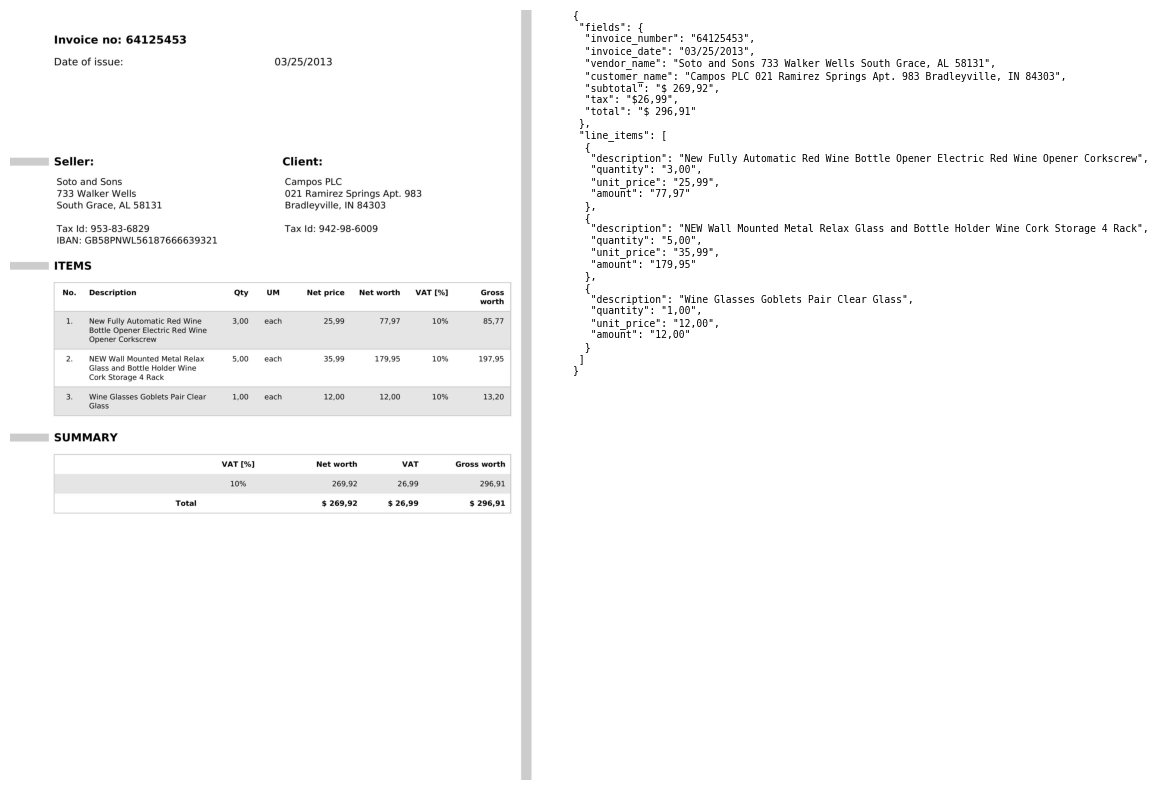

In [37]:
# Held-out set with ground truth: synthetic invoices with labelled header fields and line items.
# To use your own invoices, set LOCAL_DOCS_DIR (see the markdown above).
LOCAL_DOCS_DIR = None

def gt_to_schema(gt):
    h, s, items = gt.get("header", {}), gt.get("summary", {}), gt.get("items", [])
    return {"fields": {"invoice_number": h.get("invoice_no"), "invoice_date": h.get("invoice_date"),
                       "vendor_name": h.get("seller"), "customer_name": h.get("client"),
                       "subtotal": s.get("total_net_worth"), "tax": s.get("total_vat"), "total": s.get("total_gross_worth")},
            "line_items": [{"description": it.get("item_desc"), "quantity": it.get("item_qty"),
                            "unit_price": it.get("item_net_price"), "amount": it.get("item_net_worth")} for it in items]}

def build_docs_local(folder):
    folder = Path(folder)
    labels = json.loads((folder / "labels.json").read_text())      # {"file.png": {"fields": {...}, "line_items": [...]}}
    docs = []
    for i, (fname, gt) in enumerate(labels.items()):
        gt.setdefault("fields", {}); gt.setdefault("line_items", [])
        docs.append(dict(doc_id=f"L{i:03d}", image=Image.open(folder / fname).convert("RGB"), gt=gt))
    return docs

if LOCAL_DOCS_DIR:
    all_docs = build_docs_local(LOCAL_DOCS_DIR)
    dev_docs, test_docs = all_docs[:max(3, len(all_docs) // 3)], all_docs[max(3, len(all_docs) // 3):][:N_TEST]
else:
    from datasets import load_dataset
    dsd = load_dataset("katanaml-org/invoices-donut-data-v1")
    print("splits:", {k: len(v) for k, v in dsd.items()})
    dev_split = "validation" if "validation" in dsd else "train"

    def build_docs(split, n, prefix):
        rows = dsd[split].shuffle(seed=SEED).select(range(min(n, len(dsd[split]))))
        docs = []
        for i, r in enumerate(rows):
            gt = json.loads(r["ground_truth"]); gt = gt.get("gt_parse", gt)
            docs.append(dict(doc_id=f"{prefix}{i:03d}", image=r["image"].convert("RGB"), gt=gt_to_schema(gt)))
        return docs

    dev_docs = build_docs(dev_split, 10, "d")      # DEV: tune rules and settings on these
    test_docs = build_docs("test", N_TEST, "t")    # HELD-OUT: only used for the final comparison

print(f"dev docs: {len(dev_docs)} | held-out test docs: {len(test_docs)}")

d0 = dev_docs[0]
fig, ax = plt.subplots(1, 2, figsize=(13, 8), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].imshow(d0["image"]); ax[0].axis("off")
ax[1].axis("off"); ax[1].text(0, 1, json.dumps(d0["gt"], indent=1)[:1800], va="top", family="monospace", fontsize=7)
plt.tight_layout(); plt.show()

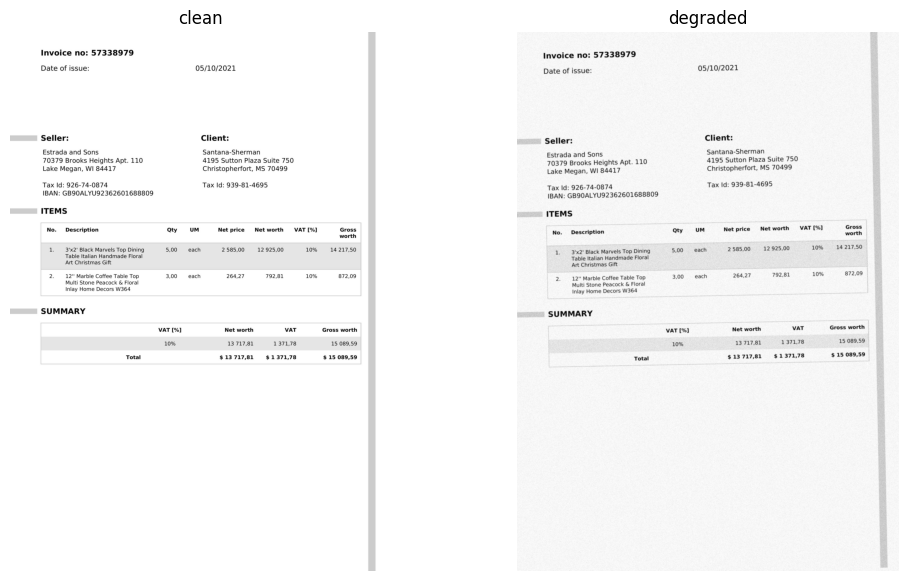

In [38]:
def degrade(img, seed):
    # make a clean invoice look like a poor scan: small rotation, blur, noise and heavy JPEG compression
    rng = np.random.default_rng(seed)
    a = np.array(img.convert("L"))
    H, W = a.shape
    M = cv2.getRotationMatrix2D((W / 2, H / 2), float(rng.uniform(-4, 4)), 1.0)
    a = cv2.warpAffine(a, M, (W, H), borderMode=cv2.BORDER_CONSTANT, borderValue=255)
    a = cv2.GaussianBlur(a, (0, 0), 1.2)
    a = np.clip(a.astype(np.float32) + rng.normal(0, 18, a.shape), 0, 255).astype(np.uint8)
    ok, enc = cv2.imencode(".jpg", a, [cv2.IMWRITE_JPEG_QUALITY, 35])
    return Image.fromarray(cv2.imdecode(enc, cv2.IMREAD_GRAYSCALE)).convert("RGB")

hard_docs = [dict(doc_id=f"h{i:03d}", image=degrade(d["image"], i), gt=d["gt"]) for i, d in enumerate(test_docs[:N_HARD])]

fig, ax = plt.subplots(1, 2, figsize=(12, 7))
ax[0].imshow(test_docs[0]["image"]); ax[0].set_title("clean"); ax[1].imshow(hard_docs[0]["image"]); ax[1].set_title("degraded")
for a in ax: a.axis("off")
plt.show()

## 3. Day 1: How VLMs work

A vision-language model is three parts joined together:

1. a **vision encoder** that turns the image into a grid of vectors (patch embeddings)
2. a small **projector** that maps those vectors into the language model's input space
3. a **large language model** that reads the image tokens and your text tokens together and writes the answer

**Visual instruction tuning** (LLaVA) trains the combination on image + instruction + answer examples, so the model learns to follow questions about pictures. The key practical fact: **a picture becomes tokens**, so a bigger image means more tokens, more memory and a slower answer. Qwen3-VL also reads images at their native resolution, which is why it is strong at reading text and documents.

Model used here: **Qwen3-VL-4B-Instruct** (Apache 2.0), which fits on a T4 in 16-bit precision. Read the architecture notes on the model card and the LLaVA project page before answering the questions below.

In [39]:
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

major = torch.cuda.get_device_capability()[0] if dev == "cuda" else 0
DTYPE = torch.bfloat16 if major >= 8 else torch.float16        # a T4 has no native bfloat16
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = Qwen3VLForConditionalGeneration.from_pretrained(MODEL_ID, dtype=DTYPE, device_map="auto").eval()
print(f"{MODEL_ID} loaded in {DTYPE} | GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Qwen/Qwen3-VL-4B-Instruct loaded in torch.float16 | GPU memory used: 5.7 GB


In [40]:
def fit_image(img, max_side=1344):
    img = img.convert("RGB"); w, h = img.size
    s = max_side / max(w, h)
    if s < 1: img = img.resize((max(64, int(w * s)), max(64, int(h * s))), Image.LANCZOS)
    if min(img.size) < 64: img = img.resize((max(64, img.size[0]), max(64, img.size[1])), Image.LANCZOS)
    return img

@torch.no_grad()
def vlm_chat(img, prompt, max_new_tokens=512, max_side=1344):
    content = ([{"type": "image", "image": fit_image(img, max_side)}] if img is not None else []) + [{"type": "text", "text": prompt}]
    inputs = processor.apply_chat_template([{"role": "user", "content": content}], tokenize=True,
                                           add_generation_prompt=True, return_dict=True, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    gen = out[:, inputs["input_ids"].shape[1]:]
    return processor.batch_decode(gen, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip()

def parse_json(text):
    t = text.strip()
    m = re.search(r"```(?:json)?\s*(.*?)```", t, re.S)
    if m: t = m.group(1).strip()
    a, b = t.find("{"), t.rfind("}")
    if a == -1 or b == -1: raise ValueError("no JSON object found in the answer")
    return json.loads(t[a:b + 1])

def vlm_json(img, prompt, schema, max_retries=2, max_new_tokens=900):
    # ask for JSON, validate against the schema, and if it fails send the error back and ask for a corrected answer
    text = vlm_chat(img, prompt, max_new_tokens)
    err = None
    for attempt in range(1, max_retries + 2):
        try:
            obj = parse_json(text); validate(obj, schema)
            return dict(obj=obj, valid=True, attempts=attempt, raw=text)
        except (ValueError, ValidationError) as e:
            err = str(e).splitlines()[0][:200]
            if attempt > max_retries: break
            text = vlm_chat(img, prompt + f"\n\nYour previous answer was not valid ({err}). Return ONLY one corrected JSON object "
                                          f"that follows the schema exactly.\n\nPrevious answer:\n{text[:1500]}", max_new_tokens)
    return dict(obj=None, valid=False, attempts=max_retries + 1, raw=text, error=err)

parameters: 4.44B in total | vision encoder 0.42B | language model + head 4.02B

How many tokens does the picture become? (this is why resolution costs time and memory)
  longest side  224 px ->    70 visual tokens
  longest side  448 px ->   140 visual tokens
  longest side  896 px ->   588 visual tokens
  longest side 1344 px ->   850 visual tokens

Q: Describe this image in two sentences.
A: Two stylishly dressed men walk confidently on a sunlit city sidewalk, passing by a modern, blue and white electric bus from Madrid’s EMT public transport system, which proudly displays “cero emisiones” (zero emissions). The bus, marked as route M11 to Sol/Sevilla, features eco-friendly branding and is parked along a traditional European street with yellow buildings and wrought-iron balconies. 
(127.8 s)


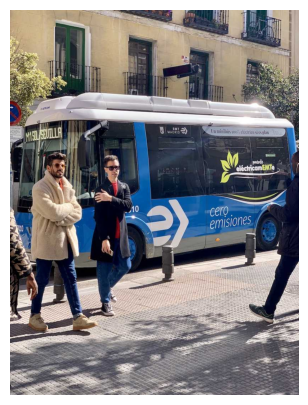

In [41]:
SAMPLE = str(ASSETS / "bus.jpg")
sample_img = Image.open(SAMPLE).convert("RGB")

total = sum(p.numel() for p in model.parameters())
vis = sum(p.numel() for n, p in model.named_parameters() if "visual" in n)
print(f"parameters: {total/1e9:.2f}B in total | vision encoder {vis/1e9:.2f}B | language model + head {(total-vis)/1e9:.2f}B")

IMG_PAD = processor.tokenizer.convert_tokens_to_ids("<|image_pad|>")
def count_visual_tokens(img, max_side):
    inputs = processor.apply_chat_template([{"role": "user", "content": [{"type": "image", "image": fit_image(img, max_side)}, {"type": "text", "text": "x"}]}],
                                           tokenize=True, add_generation_prompt=True, return_dict=True, return_tensors="pt")
    return int((inputs["input_ids"] == IMG_PAD).sum())

print("\nHow many tokens does the picture become? (this is why resolution costs time and memory)")
for ms in [224, 448, 896, 1344]:
    print(f"  longest side {ms:4d} px -> {count_visual_tokens(sample_img, ms):5d} visual tokens")

t0 = time.time()
print("\nQ: Describe this image in two sentences.\nA:", vlm_chat(sample_img, "Describe this image in two sentences.", 120), f"\n({time.time()-t0:.1f} s)")
plt.figure(figsize=(5, 5)); plt.imshow(sample_img); plt.axis("off"); plt.show()

## 4. Day 2: Visual question answering

Ask a question about an image and get a text answer. Two tests:

1. **Accuracy** on your Week 4 invoices (dev set): ask for the invoice number, date, seller, client and total, and score the answers against the ground truth with the same matching rules as Week 4.
2. **Honesty:** ask about things that are *not* on the page. A good model says `NOT FOUND`. A model that makes up a purchase-order number is hallucinating.

In [ ]:
ABSTAIN_RULE = "Answer using only what is visible in the image. Reply with the answer only, no extra words. If the answer is not in the image, reply exactly: NOT FOUND."
def ask(img, q, max_new_tokens=60): return vlm_chat(img, f"{q}\n{ABSTAIN_RULE}", max_new_tokens)

print("Natural image:")
for q in ["How many people are in the picture?", "What color is the bus?", "What is the weather like?", "What is the name of the bus company?"]:
    print(f"  Q: {q}\n  A: {ask(sample_img, q)}")

QUESTIONS = {"invoice_number": "What is the invoice number?", "invoice_date": "What is the date of issue?",
             "vendor_name": "What is the name of the seller?", "customer_name": "What is the name of the client?",
             "total": "What is the total gross worth, the final amount of the invoice?"}
rows = []
t0 = time.time()
for d in dev_docs[:8]:
    for k, q in QUESTIONS.items():
        a = ask(d["image"], q)
        rows.append(dict(doc=d["doc_id"], field=k, answer=a, correct=match_field(k, a, d["gt"]["fields"].get(k))))
vqa_df = pd.DataFrame(rows).dropna(subset=["correct"]); vqa_df["correct"] = vqa_df["correct"].astype(bool)
print(f"\nInvoice VQA on {vqa_df['doc'].nunique()} dev invoices ({time.time()-t0:.0f} s). Accuracy by field:")
display(vqa_df.groupby("field")["correct"].mean().round(2).to_frame("accuracy"))
RESULTS["vqa_invoice_acc"] = float(vqa_df["correct"].mean())
print("overall:", round(RESULTS["vqa_invoice_acc"], 3))
display(vqa_df[~vqa_df["correct"]].head(8))

Natural image:
  Q: How many people are in the picture?
  A: 4
  Q: What color is the bus?
  A: blue
  Q: What is the weather like?
  A: sunny
  Q: What is the name of the bus company?
  A: EMT MADRID


In [ ]:
# Does the model say "NOT FOUND" when the answer is not in the picture, or does it make something up?
ABSENT_Q = ["What is the purchase order number?", "What is the client's phone number?", "What is the shipping method?", "What is the SWIFT code of the bank?"]
rows = []
for d in dev_docs[:5]:
    for q in ABSENT_Q:
        a = ask(d["image"], q)
        rows.append(dict(doc=d["doc_id"], question=q, answer=a, abstained=bool(re.search(r"not found", a, re.I))))
ab = pd.DataFrame(rows)
RESULTS["abstain_rate"] = float(ab["abstained"].mean())
print(f"abstained correctly on {ab['abstained'].mean()*100:.0f}% of {len(ab)} questions whose answer is not in the image")
display(ab[~ab["abstained"]].head(8))
print("Check the invoices yourself: if one of these answers is really printed on the page it is a correct answer, otherwise it is a hallucination.")

## 5. Day 3: Natural-language explanations of CV output, with enforced JSON

Take the **detector output** (from Week 3's YOLO) plus the image, and ask the VLM for a human-readable explanation, as **JSON that matches a schema**.

**How the schema is enforced here:** the prompt shows the expected JSON, the answer is **validated** with `jsonschema`, and if it fails, the error is sent back and the model is asked to correct it (up to 2 retries). This is the baseline. **Constrained decoding** libraries such as Outlines go further: at every step they allow only the tokens that keep the output valid, so the result is valid by construction. That is the next step if the retry loop is not reliable enough, and the `Outlines` docs in the plan are the place to start.

Measured below: first-try validity, validity after retries, and **faithfulness** (does the explanation mention an object the detector never reported?).

In [ ]:
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

det = YOLO("yolo11n.pt")
cd = check_det_dataset("coco128.yaml")                      # 128 COCO photos (about 7 MB)
coco_dir = Path(cd["train"][0] if isinstance(cd["train"], (list, tuple)) else cd["train"])
coco_paths = sorted(coco_dir.glob("*.jpg"))
coco_names = cd["names"] if isinstance(cd["names"], dict) else dict(enumerate(cd["names"]))
print(len(coco_paths), "images in", coco_dir)

EXPLAIN_SCHEMA = {
    "type": "object", "additionalProperties": False, "required": ["summary", "detections", "overall_confidence"],
    "properties": {
        "summary": {"type": "string"},
        "detections": {"type": "array", "items": {"type": "object", "additionalProperties": False, "required": ["label", "verdict", "reason"],
                       "properties": {"label": {"type": "string"}, "verdict": {"enum": ["confirmed", "doubtful"]}, "reason": {"type": "string"}}}},
        "overall_confidence": {"enum": ["low", "medium", "high"]}}}
EXPLAIN_HINT = {"summary": "one or two plain sentences", "detections": [{"label": "person", "verdict": "confirmed", "reason": "short reason"}],
                "overall_confidence": "low | medium | high"}

def explain_detections(path):
    img = Image.open(path).convert("RGB")
    r = det(str(path), verbose=False)[0]
    dets = [dict(label=r.names[int(b.cls)], confidence=round(float(b.conf), 2)) for b in r.boxes]
    prompt = ("An object detector analysed this image and reported:\n" + json.dumps(dets) + "\n\n"
              "Look at the image and explain the result for a non-technical reader. For every detection say whether it looks 'confirmed' "
              "or 'doubtful' in the image, with a short reason. Do not mention objects that are not in the detector list.\n"
              "Return ONLY one JSON object shaped like this example:\n" + json.dumps(EXPLAIN_HINT, indent=1))
    res = vlm_json(img, prompt, EXPLAIN_SCHEMA, max_retries=2, max_new_tokens=500)
    invented = []
    if res["obj"]:
        known = {d["label"] for d in dets}
        invented = [x["label"] for x in res["obj"]["detections"] if x["label"] not in known]
    return img, dets, res, invented

rng = random.Random(SEED)
explain_set = rng.sample(coco_paths, 12)
rows, shown = [], None
t0 = time.time()
for p in explain_set:
    img, dets, res, invented = explain_detections(p)
    rows.append(dict(image=p.name, n_detections=len(dets), valid_first_try=res["valid"] and res["attempts"] == 1,
                     valid_after_retries=res["valid"], attempts=res["attempts"], invented_labels=len(invented)))
    if shown is None and res["valid"] and dets: shown = (img, dets, res)
ex_df = pd.DataFrame(rows); display(ex_df)
RESULTS["explain"] = dict(first_try=float(ex_df["valid_first_try"].mean()), after_retries=float(ex_df["valid_after_retries"].mean()),
                          invented_rate=float((ex_df["invented_labels"] > 0).mean()))
print(f"schema-valid on first try: {RESULTS['explain']['first_try']*100:.0f}% | after up to 2 retries: {RESULTS['explain']['after_retries']*100:.0f}% | "
      f"answers that mention an object the detector did not report: {RESULTS['explain']['invented_rate']*100:.0f}% | {time.time()-t0:.0f} s")
if shown:
    img, dets, res = shown
    plt.figure(figsize=(6, 5)); plt.imshow(img); plt.axis("off"); plt.show()
    print("detector said:", dets); print(json.dumps(res["obj"], indent=1))

128 images in /content/datasets/coco128/images/train2017


## 6. Schema-constrained invoice extraction and the three-way benchmark

The VLM reads each invoice and returns the **same JSON schema as Week 4** (fields and line items). The prompt forbids guessing and asks for `null` when a value is not visible.

Then each system is scored on the same held-out invoices, clean and degraded, with the Week 4 metrics, plus a **hallucination check**: how many returned numbers cannot be found by OCR anywhere on the page, and whether `subtotal + tax = total` and the line items add up to the subtotal.

In [ ]:
INVOICE_SCHEMA = {
    "type": "object", "additionalProperties": False, "required": ["fields", "line_items"],
    "properties": {
        "fields": {"type": "object", "additionalProperties": False, "required": FIELDS,
                   "properties": {k: {"type": ["string", "number", "null"]} for k in FIELDS}},
        "line_items": {"type": "array", "items": {"type": "object", "additionalProperties": False, "required": ITEM_KEYS,
                       "properties": {k: {"type": ["string", "number", "null"]} for k in ITEM_KEYS}}}}}
INVOICE_HINT = {"fields": {"invoice_number": "string or null", "invoice_date": "string or null, as printed", "vendor_name": "string or null",
                           "customer_name": "string or null", "subtotal": "number or null", "tax": "number or null", "total": "number or null"},
                "line_items": [{"description": "string", "quantity": "number or null", "unit_price": "number or null", "amount": "number or null"}]}
INVOICE_PROMPT = ("Extract the data from this invoice.\nRules:\n"
                  "- Copy values exactly as printed. Never guess, and never calculate a value that is not printed. Use null when a value is not visible.\n"
                  "- Amounts and quantities are plain numbers with a dot as decimal separator, without currency symbols or thousands separators.\n"
                  "- 'amount' of a line item is the row's line total (the net worth if the table has net and gross columns); subtotal is the total net worth, "
                  "tax is the total VAT, total is the total gross worth.\n"
                  "- Put one entry in line_items for every row of the items table.\n"
                  "Return ONLY one JSON object shaped like this example:\n" + json.dumps(INVOICE_HINT, indent=1))

VLM_NAME = "VLM (Qwen3-VL-4B)"
def vlm_invoice(doc):
    t0 = time.time()
    res = vlm_json(doc["image"], INVOICE_PROMPT, INVOICE_SCHEMA, max_retries=2, max_new_tokens=1100)
    out = empty_doc(doc["doc_id"], VLM_NAME)
    if res["obj"]:
        out["fields"].update({k: v for k, v in res["obj"]["fields"].items() if k in FIELDS})
        out["line_items"] = [{k: it.get(k) for k in ITEM_KEYS} for it in res["obj"]["line_items"]]
    out["meta"] = dict(latency_s=time.time() - t0, pages=1, attempts=res["attempts"],
                       schema_valid=res["valid"], schema_valid_first_try=bool(res["valid"] and res["attempts"] == 1))
    return out

def run_vlm(docs, label):
    outs = []
    for i, d in enumerate(docs):
        outs.append(vlm_invoice(d))
        if (i + 1) % 5 == 0 or i + 1 == len(docs): print(f"  {label}: {i + 1}/{len(docs)} done")
    return outs

# quick check on 2 dev invoices (look at the result before the long run)
o = vlm_invoice(dev_docs[0])
print(json.dumps({k: o[k] for k in ["fields", "line_items"]}, indent=1)[:1800]); print(o["meta"])
print("GROUND TRUTH:", json.dumps(dev_docs[0]["gt"]["fields"]))

In [ ]:
t0 = time.time()
vlm_clean = run_vlm(test_docs, "held-out clean")
vlm_hard = run_vlm(hard_docs, "held-out degraded")
print(f"VLM extraction finished in {(time.time() - t0) / 60:.1f} min")
v = vlm_clean + vlm_hard
RESULTS["vlm_schema"] = dict(first_try=float(np.mean([o["meta"]["schema_valid_first_try"] for o in v])),
                             final=float(np.mean([o["meta"]["schema_valid"] for o in v])), docs=len(v))
print(f"VLM output schema-valid on the first try: {RESULTS['vlm_schema']['first_try']*100:.0f}% | after retries: {RESULTS['vlm_schema']['final']*100:.0f}% ({len(v)} documents)")

In [ ]:
_streams = {}
def digit_stream(doc):
    # all digits that OCR can read on the page, concatenated (separators removed)
    if doc["doc_id"] not in _streams:
        _streams[doc["doc_id"]] = re.sub(r"\D", "", pytesseract.image_to_string(doc["image"].convert("L"), config="--psm 6"))
    return _streams[doc["doc_id"]]

def num_variants(v):
    out = {re.sub(r"\D", "", f"{v:.2f}")}
    if abs(v - round(v)) < 1e-9: out.add(str(int(round(v))))
    return {s for s in out if len(s) >= 3}

def hallucination_report(outs, docs):
    checked = bad = arith_n = arith_ok = sum_n = sum_ok = 0
    for o, d in zip(outs, docs):
        stream = digit_stream(d)
        nums = [o["fields"].get(k) for k in ("subtotal", "tax", "total")] + [it.get(k) for it in o["line_items"] for k in ("unit_price", "amount")]
        for v in nums:
            x = to_number(v)
            if x is None or abs(x) < 1: continue
            checked += 1
            if not any(s in stream for s in num_variants(abs(x))): bad += 1
        sub, tax, tot = (to_number(o["fields"].get(k)) for k in ("subtotal", "tax", "total"))
        if None not in (sub, tax, tot):
            arith_n += 1; arith_ok += abs(sub + tax - tot) <= 0.02
        amts = [to_number(it.get("amount")) for it in o["line_items"]]
        if sub is not None and amts and None not in amts:
            sum_n += 1; sum_ok += abs(sum(amts) - sub) <= 0.05
    return dict(ungrounded=bad / max(checked, 1), numbers_checked=checked,
                subtotal_plus_tax_equals_total=arith_ok / max(arith_n, 1), line_items_sum_to_subtotal=sum_ok / max(sum_n, 1))

print("VLM, clean held-out set:", {k: round(v, 3) for k, v in hallucination_report(vlm_clean, test_docs).items()})
print("(ungrounded = a number the model returned that OCR cannot find anywhere on the page: a sign of a made-up value.\n"
      " The arithmetic checks flag totals that do not add up. A real invoice can fail them too, so read failures as 'look at this one'.)")

### Three-way comparison: self-hosted OCR vs managed service vs VLM

In [ ]:
W4 = {}
if WEEK4_OUTPUTS and Path(WEEK4_OUTPUTS).exists():
    W4 = json.loads(Path(WEEK4_OUTPUTS).read_text())
    print("Week 4 systems loaded:", list(W4))
else:
    print("No Week 4 outputs loaded: the table below shows the VLM only. Export them from the Week 4 notebook (snippet above) and set WEEK4_OUTPUTS.")

def aligned(outs, docs):
    by_id = {o["doc_id"]: o for o in outs}
    return [by_id.get(d["doc_id"]) or empty_doc(d["doc_id"], "missing") for d in docs]

ALL = {name: {"clean": aligned(c["clean"], test_docs), "degraded": aligned(c["degraded"], hard_docs)} for name, c in W4.items()}
ALL[VLM_NAME] = {"clean": vlm_clean, "degraded": vlm_hard}

def cost_per_1000(name, lat):
    if name == VLM_NAME: return VLM_USD_PER_HOUR * lat / 3600 * 1000
    if name.startswith("Self-hosted"): return SELF_HOSTED_USD_PER_HOUR * lat / 3600 * 1000
    return MANAGED_USD_PER_1000

rows = []
for name, c in ALL.items():
    sc, sh = evaluate(c["clean"], test_docs), evaluate(c["degraded"], hard_docs)
    hr = hallucination_report(c["clean"], test_docs)
    first = float(np.mean([o["meta"].get("schema_valid_first_try", is_valid(o)) for o in c["clean"] + c["degraded"]]))
    rows.append({"System": name,
                 "Valid JSON (first try)": f"{first*100:.0f}%",
                 "Field accuracy (clean)": round(sc["field_acc"], 3), "Field accuracy (degraded)": round(sh["field_acc"], 3),
                 "Table cell F1 (clean)": round(sc["cell_f1"], 3), "Table cell F1 (degraded)": round(sh["cell_f1"], 3),
                 "Numbers not found by OCR (clean)": f"{hr['ungrounded']*100:.0f}%",
                 "Median latency (s/page)": round(sc["latency_median"], 1),
                 "Cost per 1,000 pages (USD)": round(cost_per_1000(name, sc["latency_median"]), 2),
                 "Data leaves your machine": "yes" if ("Azure" in name or "Textract" in name) else "no"})
matrix = pd.DataFrame(rows).set_index("System").T
display(matrix)
RESULTS["three_way"] = matrix.to_dict()

md = "| Criterion | " + " | ".join(matrix.columns) + " |\n|---|" + "---|" * len(matrix.columns) + "\n"
for idx, row in matrix.iterrows(): md += f"| {idx} | " + " | ".join(str(v) for v in row.values) + " |\n"
print("Copy into your README:\n"); print(md)

In [ ]:
fail_report(vlm_clean, test_docs, "VLM | clean held-out set", n=3)
fail_report(vlm_hard, hard_docs, "VLM | degraded held-out set", n=2)

## 7. Day 4: Image captioning

A caption turns an image into **searchable text**. Two captioners are compared:

- **BLIP** (small, fast, one short sentence) for indexing many images
- **Qwen3-VL** (slower, follows instructions, can read text in the image and write longer descriptions)

**Caption or raw embedding?** A caption is human-readable, can be searched by keyword, and can hold details (names, counts, text) if the captioner mentions them, but it is lossy: if the captioner did not say it, you cannot find it. A raw embedding keeps visual similarity and concepts nobody wrote down, is fast, but is opaque and weak at exact text, counts and precise relations. Day 5 measures the difference.

The reusable code is written to `mm_utils.py` (the cell below). Commit that file next to the notebook, because Module 6 imports it.

In [ ]:
%%writefile mm_utils.py
"""Reusable caption + embedding utilities (Week 5), built to be imported by Module 6.

    from mm_utils import ClipEmbedder, BlipCaptioner, MultimodalIndex

    clip = ClipEmbedder()
    cap = BlipCaptioner()
    index = MultimodalIndex(clip.embed_images, clip.embed_texts, captioner=cap)
    index.add(images, ids=names)                       # captions + CLIP embeddings are computed here
    index.search_text("a red bus", k=5, mode="embedding")   # also: "caption", "hybrid"
    index.search_image(some_image, k=5)
    index.save("my_index"); MultimodalIndex.load("my_index", clip.embed_images, clip.embed_texts)

All embeddings are L2-normalized, so a dot product is the cosine similarity.
`MultimodalIndex` itself only needs numpy; torch/transformers are imported inside the model wrappers.
"""
import json
from pathlib import Path

import numpy as np


def _to_tensor(x):
    # transformers versions differ: some return a tensor, some an output object
    import torch
    if torch.is_tensor(x):
        return x
    for name in ("pooler_output", "image_embeds", "text_embeds"):
        if getattr(x, name, None) is not None:
            return getattr(x, name)
    return x[0]


class ClipEmbedder:
    """CLIP image and text encoders that share one embedding space."""

    def __init__(self, name="openai/clip-vit-base-patch32", device=None, batch_size=32):
        import torch
        from transformers import CLIPModel, CLIPProcessor
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model = CLIPModel.from_pretrained(name).to(self.device).eval()
        self.processor = CLIPProcessor.from_pretrained(name)
        self.batch_size = batch_size
        self.dim = self.model.config.projection_dim

    def embed_images(self, images):
        import torch
        import torch.nn.functional as F
        out = []
        with torch.no_grad():
            for i in range(0, len(images), self.batch_size):
                batch = [im.convert("RGB") for im in images[i:i + self.batch_size]]
                inputs = self.processor(images=batch, return_tensors="pt").to(self.device)
                f = _to_tensor(self.model.get_image_features(**inputs))
                out.append(F.normalize(f.float(), dim=-1).cpu().numpy())
        return np.concatenate(out) if out else np.zeros((0, self.dim), dtype=np.float32)

    def embed_texts(self, texts):
        import torch
        import torch.nn.functional as F
        out = []
        with torch.no_grad():
            for i in range(0, len(texts), self.batch_size):
                batch = [t if t.strip() else " " for t in texts[i:i + self.batch_size]]
                inputs = self.processor(text=batch, return_tensors="pt", padding=True,
                                        truncation=True, max_length=77).to(self.device)
                f = _to_tensor(self.model.get_text_features(**inputs))
                out.append(F.normalize(f.float(), dim=-1).cpu().numpy())
        return np.concatenate(out) if out else np.zeros((0, self.dim), dtype=np.float32)


class BlipCaptioner:
    """Short natural-language captions with BLIP (small and fast, good for indexing many images)."""

    def __init__(self, name="Salesforce/blip-image-captioning-base", device=None, batch_size=16):
        import torch
        from transformers import BlipForConditionalGeneration, BlipProcessor
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.processor = BlipProcessor.from_pretrained(name)
        self.model = BlipForConditionalGeneration.from_pretrained(name).to(self.device).eval()
        self.batch_size = batch_size

    def __call__(self, images, max_new_tokens=40, num_beams=3):
        import torch
        caps = []
        with torch.no_grad():
            for i in range(0, len(images), self.batch_size):
                batch = [im.convert("RGB") for im in images[i:i + self.batch_size]]
                inputs = self.processor(images=batch, return_tensors="pt").to(self.device)
                ids = self.model.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=num_beams)
                caps += [c.strip() for c in self.processor.batch_decode(ids, skip_special_tokens=True)]
        return caps


def _z(s):
    # z-score a score vector so that image-text and text-text similarities can be blended fairly
    return (s - s.mean()) / (s.std() + 1e-8)


class MultimodalIndex:
    """A small searchable store of images, their captions, and two embeddings per item.

    search_text modes:
      "embedding": query text vs the image embedding (cross-modal CLIP). Best for visual concepts.
      "caption":   query text vs the embedded caption (text-to-text). Best when captions hold the details
                   (names, counts, text in the image) and for plain-text/keyword use.
      "hybrid":    z-scored blend of the two.
    """

    def __init__(self, embed_images, embed_texts, captioner=None):
        self.embed_images, self.embed_texts, self.captioner = embed_images, embed_texts, captioner
        self.ids, self.captions = [], []
        self.img_emb = None
        self.cap_emb = None

    def __len__(self):
        return len(self.ids)

    def add(self, images, ids=None, captions=None):
        n = len(images)
        ids = list(ids) if ids is not None else [f"img{len(self.ids) + i}" for i in range(n)]
        if captions is None:
            captions = list(self.captioner(images)) if self.captioner is not None else [""] * n
        ie = np.asarray(self.embed_images(images), dtype=np.float32)
        ce = np.asarray(self.embed_texts([c if c else " " for c in captions]), dtype=np.float32)
        self.ids += ids
        self.captions += list(captions)
        self.img_emb = ie if self.img_emb is None else np.vstack([self.img_emb, ie])
        self.cap_emb = ce if self.cap_emb is None else np.vstack([self.cap_emb, ce])

    def _rank(self, scores, k):
        order = np.argsort(-scores)[:k]
        return [dict(index=int(i), id=self.ids[i], score=float(scores[i]), caption=self.captions[i]) for i in order]

    def search_text(self, query, k=5, mode="embedding", alpha=0.5):
        q = np.asarray(self.embed_texts([query]), dtype=np.float32)[0]
        s_img, s_cap = self.img_emb @ q, self.cap_emb @ q
        if mode == "embedding":
            return self._rank(s_img, k)
        if mode == "caption":
            return self._rank(s_cap, k)
        if mode == "hybrid":
            return self._rank(alpha * _z(s_img) + (1 - alpha) * _z(s_cap), k)
        raise ValueError("mode must be 'embedding', 'caption' or 'hybrid'")

    def search_image(self, image, k=5):
        q = np.asarray(self.embed_images([image]), dtype=np.float32)[0]
        return self._rank(self.img_emb @ q, k)

    def describe(self, image):
        """Caption + embedding for one arbitrary image (the building block for Module 6)."""
        caption = self.captioner([image])[0] if self.captioner is not None else ""
        return dict(caption=caption, embedding=np.asarray(self.embed_images([image]), dtype=np.float32)[0])

    def save(self, folder):
        folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(folder / "embeddings.npz", img=self.img_emb, cap=self.cap_emb)
        (folder / "meta.json").write_text(json.dumps({"ids": self.ids, "captions": self.captions}, indent=1))

    @classmethod
    def load(cls, folder, embed_images, embed_texts, captioner=None):
        folder = Path(folder)
        idx = cls(embed_images, embed_texts, captioner)
        z = np.load(folder / "embeddings.npz")
        meta = json.loads((folder / "meta.json").read_text())
        idx.img_emb, idx.cap_emb = z["img"], z["cap"]
        idx.ids, idx.captions = meta["ids"], meta["captions"]
        return idx

In [ ]:
import mm_utils
from mm_utils import BlipCaptioner

blip = BlipCaptioner()

def caption_qwen(img, detailed=False):
    if detailed: return vlm_chat(img, "Describe this image in three sentences: the objects, the setting, and any text you can read.", 160)
    return vlm_chat(img, "Write one short caption for this image, under 15 words.", 40)

demo = [Image.open(ASSETS / "zidane.jpg").convert("RGB"), sample_img] + [Image.open(p).convert("RGB") for p in coco_paths[:2]] + [dev_docs[0]["image"]]
rows = []
for i, im in enumerate(demo):
    t0 = time.time(); b = blip([im])[0]; tb = time.time() - t0
    t0 = time.time(); q = caption_qwen(im); tq = time.time() - t0
    t0 = time.time(); qd = caption_qwen(im, detailed=True); tqd = time.time() - t0
    rows.append({"image": ["zidane", "bus", "coco 1", "coco 2", "invoice"][i], "BLIP": b, "Qwen3-VL short": q, "Qwen3-VL detailed": qd,
                 "BLIP s": round(tb, 1), "Qwen short s": round(tq, 1), "Qwen detailed s": round(tqd, 1)})
cap_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 140)
display(cap_df[["image", "BLIP", "Qwen3-VL short", "Qwen3-VL detailed"]]); display(cap_df[["image", "BLIP s", "Qwen short s", "Qwen detailed s"]])

## 8. Day 5: Multimodal embeddings with CLIP and retrieval

**CLIP** trains an image encoder and a text encoder together so that a picture and its description land close together in one shared space. Then:

- **text to image:** embed the query text and return the nearest image embeddings
- **image to image:** embed the query image and return the nearest image embeddings
- **caption search:** embed the *captions* and compare them with the query text (text to text)

The index below stores 128 COCO photos, their BLIP captions and both embeddings. Retrieval is scored automatically with the COCO label files: for each of 20 queries ("a photo of a dog"), a result counts as correct if that class is annotated in the image.

In [ ]:
from mm_utils import ClipEmbedder, MultimodalIndex

clip = ClipEmbedder()
index = MultimodalIndex(clip.embed_images, clip.embed_texts, captioner=blip)

coco_pil = [Image.open(p).convert("RGB") for p in coco_paths]
t0 = time.time()
index.add(coco_pil, ids=[p.name for p in coco_paths])          # captions (BLIP) + CLIP image embeddings + caption embeddings
print(f"indexed {len(index)} images in {time.time() - t0:.0f} s | embedding size {index.img_emb.shape[1]}")
for i in range(3): print(f"  {index.ids[i]}: {index.captions[i]}")

# ground truth for an automatic check: which COCO classes appear in each image (from the label files)
img_classes = {}
for p in coco_paths:
    lab = Path(str(p).replace("/images/", "/labels/")).with_suffix(".txt")
    img_classes[p.name] = {int(l.split()[0]) for l in lab.read_text().splitlines() if l.strip()} if lab.exists() else set()
freq = Counter(c for s in img_classes.values() for c in s)
queries = [c for c, n in freq.most_common(25) if n >= 3][:20]
print(len(queries), "query classes, for example:", [coco_names[c] for c in queries[:8]])

def evaluate_retrieval(mode, k=5, template="a photo of a {}"):
    p_at_k, hit1 = [], []
    for c in queries:
        res = index.search_text(template.format(coco_names[c]), k=k, mode=mode)
        rel = [c in img_classes[r["id"]] for r in res]
        p_at_k.append(np.mean(rel)); hit1.append(rel[0])
    return dict(mode=mode, **{"precision@5": round(float(np.mean(p_at_k)), 3), "top-1 correct": round(float(np.mean(hit1)), 3)})

ret_df = pd.DataFrame([evaluate_retrieval(m) for m in ["embedding", "caption", "hybrid"]]).set_index("mode")
display(ret_df)
RESULTS["retrieval"] = ret_df.to_dict()

In [ ]:
QUERY = "a person riding a horse"
fig, axes = plt.subplots(3, 5, figsize=(17, 10))
for r, mode in enumerate(["embedding", "caption", "hybrid"]):
    res = index.search_text(QUERY, k=5, mode=mode)
    for c, hit in enumerate(res):
        axes[r, c].imshow(coco_pil[hit["index"]]); axes[r, c].axis("off")
        axes[r, c].set_title(f"{mode}\n{hit['caption'][:38]}", fontsize=8)
plt.suptitle(f'Query: "{QUERY}"'); plt.tight_layout(); plt.show()

In [ ]:
# An arbitrary image: caption it, embed it, find its nearest neighbours in the index.
# To use your own picture, upload it in the Colab file panel and set the path here.
MY_IMAGE = None            # e.g. "/content/my_photo.jpg"
img = Image.open(MY_IMAGE).convert("RGB") if MY_IMAGE else Image.open(ASSETS / "zidane.jpg").convert("RGB")
info = index.describe(img)
print("caption:", info["caption"], "| embedding shape:", info["embedding"].shape, "| norm:", round(float(np.linalg.norm(info["embedding"])), 3))
nearest = index.search_image(img, k=4)
fig, axes = plt.subplots(1, 5, figsize=(17, 4))
axes[0].imshow(img); axes[0].set_title("query image");
for a, hit in zip(axes[1:], nearest):
    a.imshow(coco_pil[hit["index"]]); a.set_title(f"{hit['score']:.2f}  {hit['caption'][:30]}", fontsize=8)
for a in axes: a.axis("off")
plt.show()

index.save("mm_index")
reloaded = MultimodalIndex.load("mm_index", clip.embed_images, clip.embed_texts)
same = reloaded.search_text(QUERY, k=1)[0]["id"] == index.search_text(QUERY, k=1)[0]["id"]
print("saved the index to ./mm_index and reloaded it; same top result for the query:", same)

## 9. Success gate

In [ ]:
v = RESULTS.get("vlm_schema", {})
print("GATE 1: the VLM returns schema-valid answers on test images")
print(f"  invoices: {v.get('final', 0)*100:.0f}% valid after up to 2 retries ({v.get('first_try', 0)*100:.0f}% on the first try), {v.get('docs', 0)} documents")
e = RESULTS.get("explain", {})
print(f"  explanations of detector output: {e.get('after_retries', 0)*100:.0f}% valid ({e.get('first_try', 0)*100:.0f}% first try)")
print("\nGATE 2: caption + embed an arbitrary image and retrieve the nearest image to a text query")
top = index.search_text(QUERY, k=1)[0]
print(f"  query {QUERY!r} -> top result {top['id']} (caption: {top['caption']!r})")
print("  retrieval check:", RESULTS.get("retrieval", {}).get("precision@5"))
print("  reusable utilities: mm_utils.py (ClipEmbedder, BlipCaptioner, MultimodalIndex) -> commit it next to the notebook")